In [9]:

import pandas as pd
from sklearn.preprocessing import StandardScaler

# 1. Load the dataset (fixed the double .parquet typo)
df = pd.read_parquet('../data/network_intrusion_clustering.parquet')

# 2. Drop Label — clustering is unsupervised, Label used only for evaluation
# Notice we are using 'df' here, not 'df_clustering'
X = df.drop(columns=['Label'])
y = df['Label']  # saved for post-hoc interpretation

# 3. Standardize features (zero mean, unit variance)
scaler = StandardScaler()
X_scaled = scaler.fit_transform(X)

print(f"Feature matrix shape : {X_scaled.shape}")
print(f"Label series shape   : {y.shape}")
print("All scaled with standart scaler ")

Feature matrix shape : (50420, 25)
Label series shape   : (50420,)
All scaled with standart scaler 


k= 2 | Inertia:    1061440.9 | Silhouette: 0.5135 | Davies-Bouldin: 1.6709
k= 3 | Inertia:     985327.9 | Silhouette: 0.6301 | Davies-Bouldin: 1.2235
k= 4 | Inertia:     896926.3 | Silhouette: 0.4937 | Davies-Bouldin: 1.3371
k= 5 | Inertia:     813464.2 | Silhouette: 0.4205 | Davies-Bouldin: 1.4093
k= 6 | Inertia:     750604.5 | Silhouette: 0.4320 | Davies-Bouldin: 1.2638
k= 7 | Inertia:     687251.9 | Silhouette: 0.4329 | Davies-Bouldin: 1.1453
k= 8 | Inertia:     653142.5 | Silhouette: 0.4562 | Davies-Bouldin: 1.0633
k= 9 | Inertia:     598468.7 | Silhouette: 0.4756 | Davies-Bouldin: 1.0775
k=10 | Inertia:     564408.3 | Silhouette: 0.4640 | Davies-Bouldin: 1.0100
k=11 | Inertia:     523751.0 | Silhouette: 0.5004 | Davies-Bouldin: 0.9618
k=12 | Inertia:     492145.4 | Silhouette: 0.4662 | Davies-Bouldin: 1.0108
k=13 | Inertia:     450920.2 | Silhouette: 0.5003 | Davies-Bouldin: 0.8448
k=14 | Inertia:     431647.8 | Silhouette: 0.4829 | Davies-Bouldin: 0.9762
k=15 | Inertia:     40635

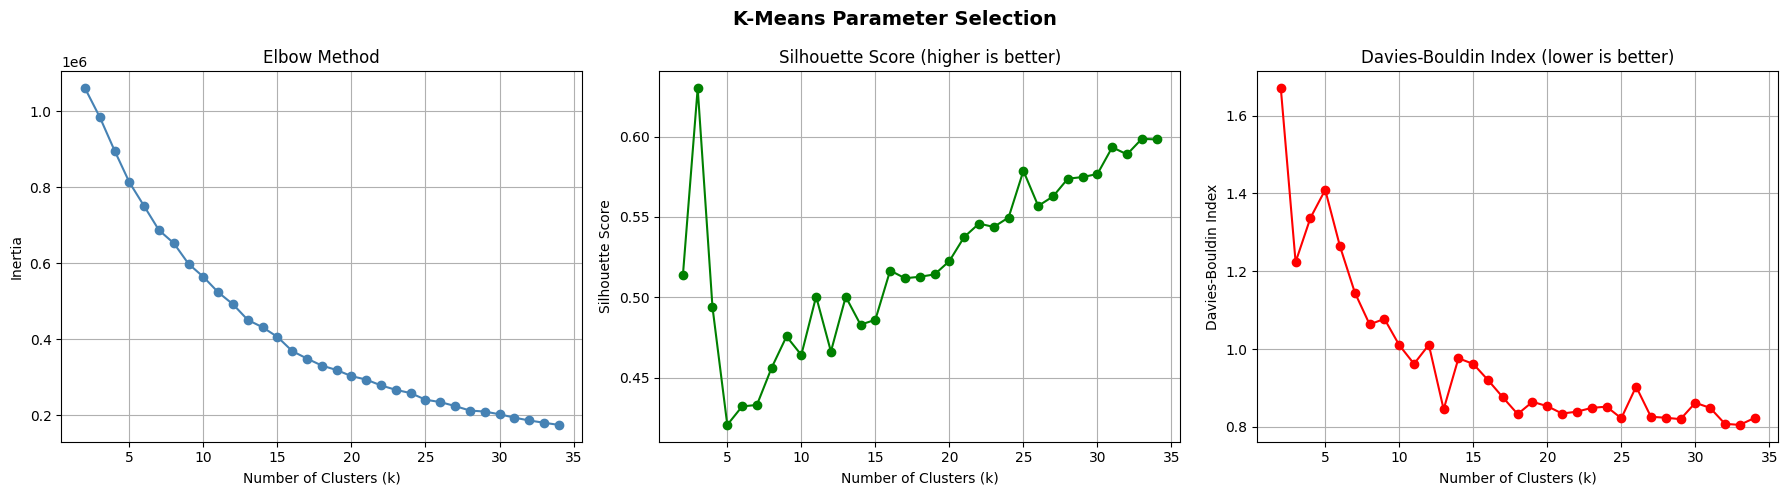


  Best k selected    : 3
   Silhouette Score  : 0.6301
   Davies-Bouldin    : 1.2235
   ARI               : 0.0872  (1.0 = perfect, 0 = random)
   NMI               : 0.0652  (1.0 = perfect, 0 = no mutual info)

 K-Means complete. Cluster labels saved to df.


In [11]:
# =============================================================
# K-MEANS CLUSTERING
# =============================================================
import numpy as np
import matplotlib.pyplot as plt
from sklearn.cluster import KMeans
from sklearn.metrics import silhouette_score, davies_bouldin_score, adjusted_rand_score, normalized_mutual_info_score

k_range = range(2, 35)

inertias          = []
silhouette_scores = []
db_scores         = []

for k in k_range:
    km = KMeans(n_clusters=k, random_state=42, n_init=10)
    labels = km.fit_predict(X_scaled)

    inertias.append(km.inertia_)
    silhouette_scores.append(silhouette_score(X_scaled, labels))
    db_scores.append(davies_bouldin_score(X_scaled, labels))

    print(f"k={k:2d} | Inertia: {km.inertia_:>12.1f} | "
          f"Silhouette: {silhouette_scores[-1]:.4f} | "
          f"Davies-Bouldin: {db_scores[-1]:.4f}")

# -------------------------------------------------------------
# Plots
# -------------------------------------------------------------
fig, axes = plt.subplots(1, 3, figsize=(18, 5))

axes[0].plot(k_range, inertias, marker='o', color='steelblue')
axes[0].set_title('Elbow Method')
axes[0].set_xlabel('Number of Clusters (k)')
axes[0].set_ylabel('Inertia')
axes[0].grid(True)

axes[1].plot(k_range, silhouette_scores, marker='o', color='green')
axes[1].set_title('Silhouette Score (higher is better)')
axes[1].set_xlabel('Number of Clusters (k)')
axes[1].set_ylabel('Silhouette Score')
axes[1].grid(True)

axes[2].plot(k_range, db_scores, marker='o', color='red')
axes[2].set_title('Davies-Bouldin Index (lower is better)')
axes[2].set_xlabel('Number of Clusters (k)')
axes[2].set_ylabel('Davies-Bouldin Index')
axes[2].grid(True)

plt.suptitle('K-Means Parameter Selection', fontsize=14, fontweight='bold')
plt.tight_layout()
plt.show()

# -------------------------------------------------------------
# Best k & Final Model
# -------------------------------------------------------------
best_k = silhouette_scores.index(max(silhouette_scores)) + 2

km_best = KMeans(n_clusters=best_k, random_state=42, n_init=10)
kmeans_labels = km_best.fit_predict(X_scaled)

# Save labels back to df
df['KMeans_Cluster'] = kmeans_labels

# -------------------------------------------------------------
# Evaluation vs Ground Truth (Label)
# -------------------------------------------------------------
ari = adjusted_rand_score(y, kmeans_labels)
nmi = normalized_mutual_info_score(y, kmeans_labels)

print(f"\n  Best k selected    : {best_k}")
print(f"   Silhouette Score  : {max(silhouette_scores):.4f}")
print(f"   Davies-Bouldin    : {db_scores[best_k - 2]:.4f}")
print(f"   ARI               : {ari:.4f}  (1.0 = perfect, 0 = random)")
print(f"   NMI               : {nmi:.4f}  (1.0 = perfect, 0 = no mutual info)")

print("\n K-Means complete. Cluster labels saved to df.")

In [12]:
# How many points per cluster
print(df['KMeans_Cluster'].value_counts())

# What labels are in each cluster
print(pd.crosstab(df['KMeans_Cluster'], df['Label']))

KMeans_Cluster
0    47377
1     2412
2      631
Name: count, dtype: int64
Label              0   1     2    3     4   5   6    7   8   9     10  11  12  \
KMeans_Cluster                                                                  
0               39860  39  2560  182  2550  78  40  118   1   8  1814  64  29   
1                1409   0     0    1   903  27  40    0   6  26     0   0   0   
2                 578   0     0   23     1   0  28    0   0   1     0   0   0   

Label           13  14  
KMeans_Cluster          
0               21  13  
1                0   0  
2                0   0  


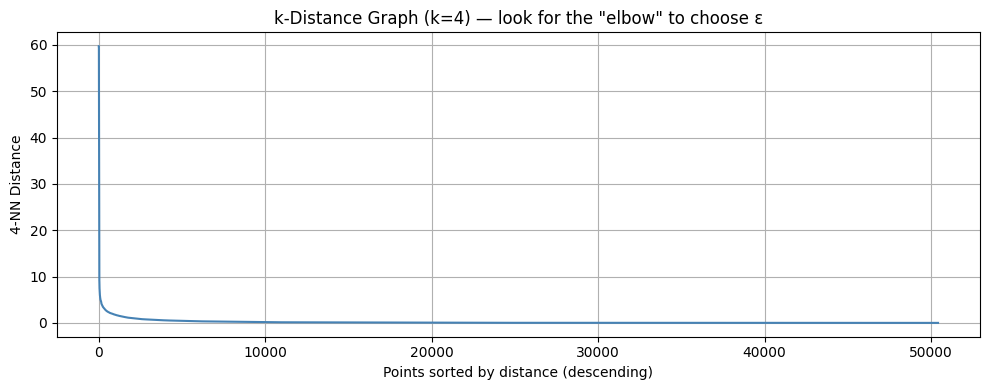

   eps | min_samp | n_clusters |  noise_% |  Silhouette |  Davies-Bouldin
------------------------------------------------------------------------
   0.3 |        5 |        314 |    13.1% | 0.10597939701078024 | 0.5508720708954367
   0.3 |       10 |        173 |    16.1% | 0.34569125989203253 | 0.512745121754624
   0.3 |       20 |        109 |    20.4% | 0.5080537556816438 | 0.45536067231376726
   0.3 |       50 |         55 |    27.1% | 0.6868455929297037 | 0.4290688852443452
   0.5 |        5 |        238 |     8.3% | 0.12043211166411902 | 0.5498919408429626
   0.5 |       10 |        124 |    10.9% | 0.23722445517762972 | 0.5447625584757096
   0.5 |       20 |         77 |    14.0% | 0.47940922664900826 | 0.5075169771730196
   0.5 |       50 |         44 |    19.2% | 0.5687900037825463 | 0.49411536896637337
   0.8 |        5 |        159 |     4.9% | 0.1160961707902614 | 0.5074468344462586
   0.8 |       10 |         77 |     6.7% | 0.3131364431799057 | 0.4684729897081908
   0.8 

KeyboardInterrupt: 

In [7]:
# =============================================================
# DBSCAN CLUSTERING
# =============================================================
import numpy as np
import matplotlib.pyplot as plt
from sklearn.cluster import DBSCAN
from sklearn.neighbors import NearestNeighbors
from sklearn.metrics import silhouette_score, davies_bouldin_score, adjusted_rand_score, normalized_mutual_info_score
from sklearn.decomposition import PCA
from itertools import product

# -------------------------------------------------------------
# Step 1: k-distance plot to estimate a good epsilon
# -------------------------------------------------------------
# Use k = min_samples - 1 (commonly 4) for the k-NN distance plot
k_nn = 4
nbrs = NearestNeighbors(n_neighbors=k_nn).fit(X_scaled)
distances, _ = nbrs.kneighbors(X_scaled)
k_distances = np.sort(distances[:, -1])[::-1]   # sort descending

plt.figure(figsize=(10, 4))
plt.plot(k_distances, color='steelblue')
plt.title(f'k-Distance Graph (k={k_nn}) — look for the "elbow" to choose ε')
plt.xlabel('Points sorted by distance (descending)')
plt.ylabel(f'{k_nn}-NN Distance')
plt.grid(True)
plt.tight_layout()
plt.show()

# -------------------------------------------------------------
# Step 2: Grid search over (eps, min_samples)
# -------------------------------------------------------------
eps_values        = [0.3, 0.5, 0.8, 1.0, 1.5, 2.0]
min_samples_values = [5, 10, 20, 50]

results = []

print(f"{'eps':>6} | {'min_samp':>8} | {'n_clusters':>10} | {'noise_%':>8} | {'Silhouette':>11} | {'Davies-Bouldin':>15}")
print("-" * 72)

for eps, min_samp in product(eps_values, min_samples_values):
    db = DBSCAN(eps=eps, min_samples=min_samp, n_jobs=-1)
    labels = db.fit_predict(X_scaled)

    n_clusters = len(set(labels)) - (1 if -1 in labels else 0)
    noise_pct  = np.sum(labels == -1) / len(labels) * 100

    # Need at least 2 clusters and some non-noise points to score
    non_noise_mask = labels != -1
    if n_clusters >= 2 and non_noise_mask.sum() > 0:
        sil = silhouette_score(X_scaled[non_noise_mask], labels[non_noise_mask])
        dbi = davies_bouldin_score(X_scaled[non_noise_mask], labels[non_noise_mask])
    else:
        sil, dbi = np.nan, np.nan

    results.append({
        'eps': eps, 'min_samples': min_samp,
        'n_clusters': n_clusters, 'noise_pct': noise_pct,
        'silhouette': sil, 'davies_bouldin': dbi
    })
    print(f"{eps:>6.1f} | {min_samp:>8} | {n_clusters:>10} | {noise_pct:>7.1f}% | "
          f"{sil if not np.isnan(sil) else 'N/A':>11} | "
          f"{dbi if not np.isnan(dbi) else 'N/A':>15}")

# -------------------------------------------------------------
# Step 3: Pick best config (highest Silhouette, noise < 30%)
# -------------------------------------------------------------
valid = [r for r in results if not np.isnan(r['silhouette']) and r['noise_pct'] < 30]
best  = max(valid, key=lambda r: r['silhouette'])

print(f"\n  Best configuration:")
print(f"   eps          : {best['eps']}")
print(f"   min_samples  : {best['min_samples']}")
print(f"   n_clusters   : {best['n_clusters']}")
print(f"   Noise points : {best['noise_pct']:.1f}%")
print(f"   Silhouette   : {best['silhouette']:.4f}")
print(f"   Davies-Bouldin: {best['davies_bouldin']:.4f}")

# -------------------------------------------------------------
# Step 4: Final DBSCAN model with best params
# -------------------------------------------------------------
db_best = DBSCAN(eps=best['eps'], min_samples=best['min_samples'], n_jobs=-1)
dbscan_labels = db_best.fit_predict(X_scaled)
df['DBSCAN_Cluster'] = dbscan_labels

# -------------------------------------------------------------
# Step 5: Evaluation vs Ground Truth
# -------------------------------------------------------------
# Exclude noise points for ARI/NMI (noise label = -1)
non_noise = dbscan_labels != -1
ari = adjusted_rand_score(y[non_noise], dbscan_labels[non_noise])
nmi = normalized_mutual_info_score(y[non_noise], dbscan_labels[non_noise])

print(f"\n   ARI  : {ari:.4f}  (1.0 = perfect, 0 = random)")
print(f"   NMI  : {nmi:.4f}  (1.0 = perfect, 0 = no mutual info)")

# -------------------------------------------------------------
# Step 6: Visualisation with PCA (2D)
# -------------------------------------------------------------
pca = PCA(n_components=2, random_state=42)
X_pca = pca.fit_transform(X_scaled)

fig, axes = plt.subplots(1, 2, figsize=(16, 6))

# — DBSCAN clusters
unique_labels = sorted(set(dbscan_labels))
colors = plt.cm.tab20(np.linspace(0, 1, len(unique_labels)))

for lbl, col in zip(unique_labels, colors):
    mask = dbscan_labels == lbl
    label_str = f'Noise ({mask.sum()})' if lbl == -1 else f'Cluster {lbl} ({mask.sum()})'
    marker = 'x' if lbl == -1 else 'o'
    alpha  = 0.3 if lbl == -1 else 0.6
    axes[0].scatter(X_pca[mask, 0], X_pca[mask, 1],
                    c=[col], label=label_str, marker=marker,
                    s=10, alpha=alpha)

axes[0].set_title(f'DBSCAN Clusters (ε={best["eps"]}, min_samples={best["min_samples"]})')
axes[0].set_xlabel('PC 1')
axes[0].set_ylabel('PC 2')
axes[0].legend(loc='upper right', fontsize=7, markerscale=2)
axes[0].grid(True)

# — Ground truth labels for comparison
unique_true = sorted(set(y))
colors_gt   = plt.cm.tab10(np.linspace(0, 1, len(unique_true)))

for lbl, col in zip(unique_true, colors_gt):
    mask = np.array(y) == lbl
    axes[1].scatter(X_pca[mask, 0], X_pca[mask, 1],
                    c=[col], label=str(lbl), s=10, alpha=0.5)

axes[1].set_title('Ground Truth Labels (for comparison)')
axes[1].set_xlabel('PC 1')
axes[1].set_ylabel('PC 2')
axes[1].legend(loc='upper right', fontsize=7, markerscale=2)
axes[1].grid(True)

plt.suptitle('DBSCAN — PCA 2D Projection', fontsize=14, fontweight='bold')
plt.tight_layout()
plt.show()

print("\n DBSCAN complete. Cluster labels saved to df.")